In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

df = pd.read_csv('spam.csv', encoding='latin-1')


In [3]:
df.head()


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
df = df[['v1','v2']]
df.columns = ['lable', 'message']
print(df.shape)
df.head()

(5572, 2)


,lable,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
print(df['lable'].value_counts())
print(df.isnull().sum().sum())
print(df.duplicated().sum())

print('--------')
df= df.drop_duplicates()
print(df.duplicated().sum())
df['lable'] = df['lable'].map({'ham':0, 'spam':1})

print('--------')
print(df.shape)
print(df['lable'].value_counts())


lable
ham     4825
spam     747
Name: count, dtype: int64
0
403
--------
0
--------
(5169, 2)
lable
0    4516
1     653
Name: count, dtype: int64


In [6]:
x_train, x_test, y_train , y_test = train_test_split(df["message"], df['lable'], test_size=0.2, random_state=42,  stratify=df['lable'])

tfidf = TfidfVectorizer()
x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

model = MultinomialNB()
model.fit(x_train_tfidf, y_train)
pred = model.predict(x_test_tfidf)

In [7]:
print('Accuracy', accuracy_score(y_test, pred))
print('Precision', precision_score(y_test, pred))
print('Recall', recall_score(y_test, pred))
print('Confusion Matrix\n', confusion_matrix(y_test, pred))

Accuracy 0.9516441005802708
Precision 1.0
Recall 0.6183206106870229
Confusion Matrix
 [[903   0]
 [ 50  81]]


## different model


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

In [9]:
models = {
    'Naive Bayes': MultinomialNB(),
    'LogisticRegression': LogisticRegression(class_weight='balanced'),
    'LinearSVC': LinearSVC(class_weight='balanced')
}

results = []
for name, model in models.items():
    model.fit(x_train_tfidf, y_train)
    p = model.predict(x_test_tfidf)
    results.append({
        'Model': name,
        'accuracy': accuracy_score(y_test, p),
        'precision': precision_score(y_test, p),
        'recall': recall_score(y_test, p),
        'f1': f1_score(y_test, p)
    })

results_df = pd.DataFrame(results).round(4)
print(results_df)

                Model  accuracy  precision  recall      f1
0         Naive Bayes    0.9516     1.0000  0.6183  0.7642
1  LogisticRegression    0.9787     0.9225  0.9084  0.9154
2           LinearSVC    0.9826     0.9748  0.8855  0.9280


In [10]:
best_model = models['LinearSVC']

def check(msg):
    v = tfidf.transform([msg])
    return 'SPAM' if best_model.predict(v)[0] == 1 else 'HAM'

print(check('Congratulations! You have won a free ticket to pakistan. Click here to claim'))
print(check('oke, i will call after lunch'))

SPAM
HAM


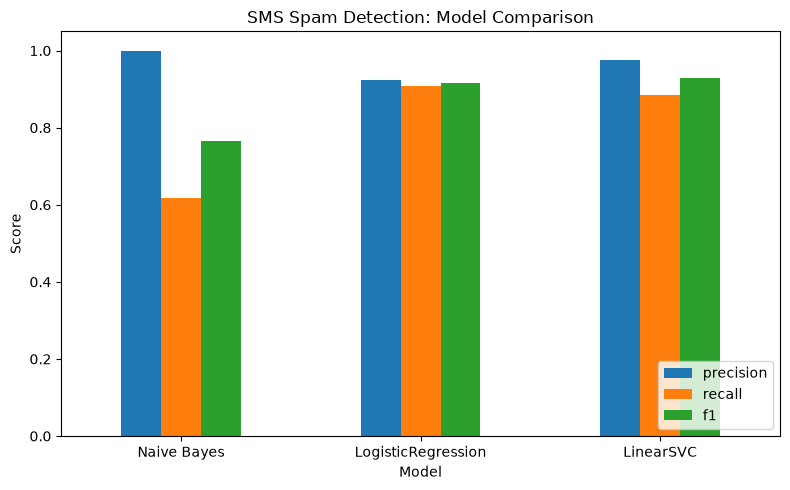

In [11]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[["precision", "recall", "f1"]].plot(kind="bar", figsize=(8, 5))
plt.title("SMS Spam Detection: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

## Conclusion
## -  Dataset: 5169 Sms ( after duplicates)
## - naive bayes precision 100% but recall 62%
## - best model: LinearSVC 
## - in spam dataset recall and precision also matters with accuracy